### # This notebook calculates 0-D RE evolution during a Disruption

 Loading Modules

In [100]:
import sys
RE_path = './' # Path to RE.py -> This file contains required functions for calculating RE-relevant quantities
sys.path.insert(1, RE_path)

In [104]:
# Import other modules
import numpy as np
from matplotlib import pyplot as plt
import scipy.constants as const
from unit_conversion import *
import importlib
import RE 
importlib.reload(RE)
from RE import *
from scipy.integrate import solve_ivp
importlib.reload(RE)

<module 'RE' from '/Users/rishabhdatta/MIT Dropbox/Rishabh Datta/Rishabh_EP_Group/Code/RE_Solver/RE.py'>

## Instantiate solver and define settings

In [111]:
solver = RE.solver0D()
solver.display() # Show default values


 Constants:
Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 0
Init. Temp. T0 [eV] = 5e+03
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 0, iCompton = 0
Secondary: iAvalanche = 1


In [117]:
# Change solver settings
solver.T0 = 20e3 # Initial temperature [eV]
solver.k = 1.0 # Elongation
solver.Ir0 = 1.0 # Initial RE Current [A]
solver.iCompton = 1 # Turn on activated sources
solver.iTritium = 1
solver.iAvalanche = 1

solver.display()


 Constants:
Major radius R0 [m] = 1.850
Minor radius a [m] = 0.570
Elongation k [-] = 1.000
ni [per cubic m] = 3e+20
Inductance L [Henry] = 1.85e-06
Btor [Tesla] = 12.2

 Initial Values and TQ:
Init. Plasma Current I0 [A] = 8.7e+06
Init. RE Current Ir0 [A] = 1
Init. Temp. T0 [eV] = 2e+04
Final Temp. Tf [eV] = 10
Temp. decay time t0 [s] = 0.0001

 Impurity Settings:
Added D density [per cubic m] = 1e-11
Added Impurity density [per cubic m] = 1e-11
Added Impurity Z, A [-] = 10, 20

 RE Source Settings: 

Primary: iDreicer = 1, iTritium = 1, iCompton = 1
Secondary: iAvalanche = 1


## Solve

In [118]:
# solve
solver.tmax = 10e-3 # end time [s]
solver.idiag = True # calculate detailed output
t, Ip, Ir, Wk = solver.solve()

Here, we will plot  𝐼𝑝 and  𝐼_𝑅𝐸 as a function of time

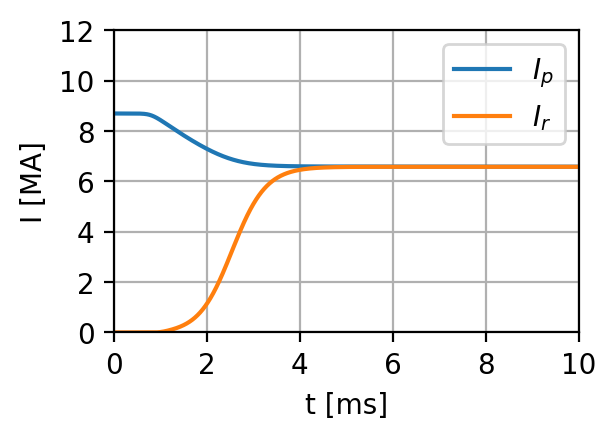

In [119]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)
plt.plot(t*1e3,Ip/1e6,label='$I_p$')
plt.plot(t*1e3,Ir/1e6,label='$I_r$')
plt.grid()
plt.xlabel('t [ms]')
plt.ylabel('I [MA]')
plt.ylim([0,12])
plt.yticks(np.arange(0,13,2))
plt.xlim([0,solver.tmax*1e3])

plt.legend()


We can also plot the RE beam energy as a function of time

Plateau Energy [MJ] = 4.842
Average RE Energy [MeV] = 18.975


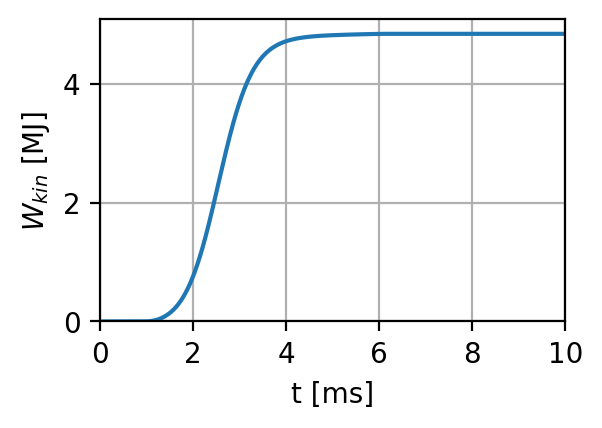

In [120]:
fig, axs = plt.subplots(1,1,figsize=(3,2),dpi=200,sharex=True)

plt.plot(t*1e3,Wk/1e6)
plt.grid()
plt.xlabel('t [ms]')
plt.ylim(ymin=0)
plt.xlim([0,solver.tmax*1e3])
axs.set_ylabel('$W_{kin}$ [MJ]')


print('Plateau Energy [MJ] = %1.3f'%(Wk[-1]/1e6))

# Estimate the average RE energy in MeV
N = Ir[-1] * (2 * np.pi * solver.R0) / (const.e * const.c)
avg_energy = Wk[-1] / N
print('Average RE Energy [MeV] = %1.3f'%(avg_energy/1e6/const.eV))


## Show detailed results

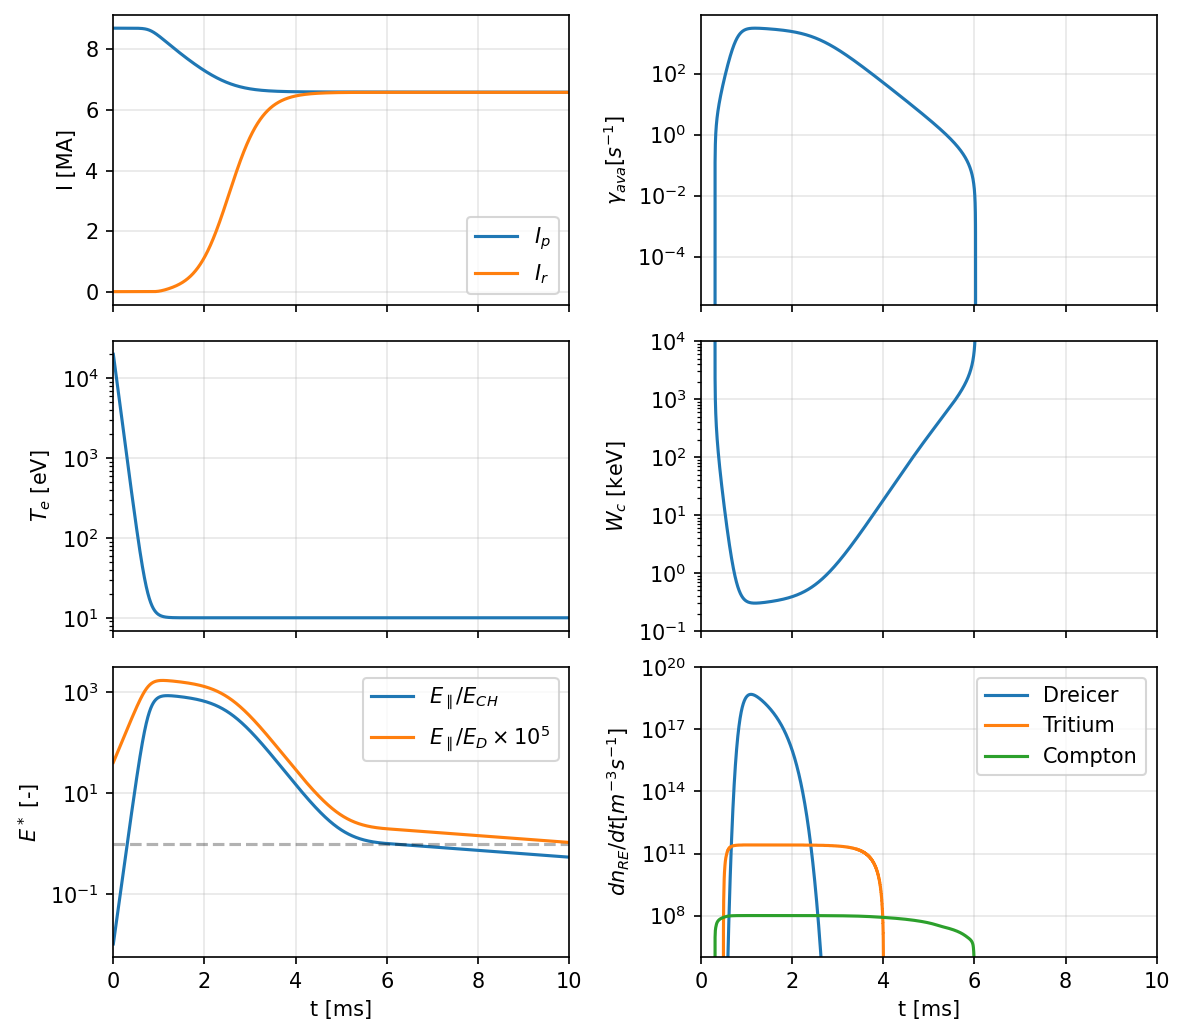

In [121]:
# Use the dictionary stored inside the solver object
d = solver.diag

fig, axs = plt.subplots(3, 2, sharex=True, figsize=(8, 7), dpi=150)

# [0,0] Currents - Compare Plasma vs Runaway
axs[0, 0].plot(d['t'] * 1e3, Ip / 1e6, label='$I_p$')
axs[0, 0].plot(d['t'] * 1e3, Ir / 1e6, label='$I_r$')
axs[0, 0].set_ylabel('I [MA]')
axs[0, 0].legend()

# [1,0] Electron Temperature
axs[1, 0].plot(d['t'] * 1e3, d['Te'])
axs[1, 0].set_ylabel('$T_e$ [eV]')
axs[1, 0].set_yscale('log')

# [2,0] Normalized Electric Fields
axs[2, 0].plot(d['t'] * 1e3, d['E_star'], label='$E_{\parallel}/E_{CH}$')
axs[2, 0].axhline(1, color='k', linestyle='--', alpha=0.3)
axs[2, 0].plot(d['t'] * 1e3, d['EoED'] * 1e5, label='$E_\parallel/E_D \\times 10^5$')
axs[2, 0].set_ylabel('$E^*$ [-]')
axs[2, 0].set_yscale('log')
axs[2, 0].legend()

# [0,1] Avalanche Growth Rate
axs[0, 1].plot(d['t'] * 1e3, d['gamma_ava'])
axs[0, 1].set_ylabel('$\gamma_{ava} [s^{-1}]$')
axs[0, 1].set_yscale('log')

# [1,1] Critical Energy (Recalculated for visualization)
# Since Wc isn't in your diag dict yet, we use the solver's imported function
from RE import getCriticalRunawayEnergy
import scipy.constants as const
Wc = getCriticalRunawayEnergy(d['E_star']) / const.eV
axs[1, 1].plot(d['t'] * 1e3, Wc / 1e3)
axs[1, 1].set_ylabel('$W_c$ [keV]')
axs[1, 1].set_yscale('log')
axs[1, 1].set_ylim([1e-1, 1e4])

# [2,1] Primary Source Rates (Dreicer, Tritium, Compton)
axs[2, 1].plot(d['t'] * 1e3, d['SD'], label='Dreicer')
axs[2, 1].plot(d['t'] * 1e3, d['ST'], label='Tritium')
axs[2, 1].plot(d['t'] * 1e3, d['SC'], label='Compton')
axs[2, 1].set_ylabel('$dn_{RE}/dt [m^{-3}s^{-1}]$')
axs[2, 1].set_yscale('log')
axs[2, 1].set_ylim([1e6, 1e20])
axs[2, 1].legend()

# Global formatting
for ax in axs.flat:
    ax.grid(True, alpha=0.3)
    ax.set_xlim([0, d['t'].max() * 1e3])

axs[2, 0].set_xlabel('t [ms]')
axs[2, 1].set_xlabel('t [ms]')
plt.tight_layout()
plt.show()